In [1]:
import os
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.metrics import (
    confusion_matrix, accuracy_score, precision_score, recall_score,
    f1_score, fbeta_score, roc_auc_score, average_precision_score
)

sns.set_style("whitegrid")
PALETTE = sns.color_palette("Set2", 8)

RANDOM_STATE = 42
RAW_DATA_PATH = "../data/ecommerce_sales_34500.csv"
MODEL_PATH = "../modelos/logistic_regression.joblib"

OUTPUT_DIR = "../figuras/impacto_economico"
os.makedirs(OUTPUT_DIR, exist_ok=True)


In [3]:
#Reproducción del split realizado al final del EDA, y cuyos datos resultantes se usaron en el entrnamiento, evaluacion y interpretabilidad SHAP de los modelos
df = pd.read_csv(RAW_DATA_PATH)

df = df.drop(columns=["order_id", "customer_id", "product_id", "order_date"])

y = (df["returned"] == "Yes").astype(int)
X = df.drop(columns="returned")

X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)

numeric_cols = [
    "price", "discount", "quantity", "delivery_time_days",
    "total_amount", "shipping_cost", "profit_margin", "customer_age"
]
cat_cols = ["category", "payment_method", "region", "customer_gender"]

# One-Hot Encoding 
ohe = OneHotEncoder(drop="first", sparse_output=False, handle_unknown="ignore")
ohe.fit(X_train_raw[cat_cols])

X_test_cat = pd.DataFrame(
    ohe.transform(X_test_raw[cat_cols]),
    columns=ohe.get_feature_names_out(cat_cols),
    index=X_test_raw.index
)

# Escalado 
scaler = StandardScaler()
scaler.fit(X_train_raw[numeric_cols])

X_test_num = pd.DataFrame(
    scaler.transform(X_test_raw[numeric_cols]),
    columns=numeric_cols,
    index=X_test_raw.index
)

X_test_proc = pd.concat([X_test_num, X_test_cat], axis=1)

print("Tamaño de X_test:", X_test_proc.shape)
print("Proporción de devoluciones:", round(y_test.mean(), 4))


Tamaño de X_test: (6900, 25)
Proporción de devoluciones: 0.0552


In [4]:
# Carga del modelo de regresión logística y predicciones sobre el conjunto de test
modelo_lr = joblib.load(MODEL_PATH)
y_pred = modelo_lr.predict(X_test_proc)
print("Predicciones realizadas:", len(y_pred))


Predicciones realizadas: 6900


c:\Users\HP\anaconda3\Lib\site-packages\sklearn\base.py:463: InconsistentVersionWarning: Trying to unpickle estimator LogisticRegression from version 1.5.2 when using version 1.8.0. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(


In [5]:
df_test = pd.DataFrame({
    "y_real": y_test.to_numpy(),
    "y_pred": y_pred,                                        #Creamos DataFrame con los valores e la variable objetivo reales del conjunto de test, las predicciones del modelo
    "total_amount": X_test_raw["total_amount"].to_numpy()
})

filas = []

for nombre, real, pred in [("VP", 1, 1), ("FN", 1, 0), ("FP", 0, 1), ("VN", 0, 0)]:  #recorremos cada caso posible en funcion de que valor tenia la variable objetivo y que se predijo
    datos = df_test[(df_test["y_real"] == real) & (df_test["y_pred"] == pred)]   #filtramos en esta linea para quedarnos con los que corresponde a cada caso (VP, FN, ...)      
    filas.append([nombre, len(datos), datos["total_amount"].sum()]) #Para cada caso, nos guardamos la suma de los importes de los VP, FN, FP, VN

tabla_importes = pd.DataFrame(
    filas,
    columns=["Resultado", "N", "Suma total_amount (USD)"]    #construimos tabla con la suma de los importes de los pedidos de cada uno de los bloques de la matriz de confusion
)

from IPython.display import HTML, display
display(HTML(tabla_importes.to_html(index=False)))
print(tabla_importes.to_string(index=False))

Resultado,N,Suma total_amount (USD)
VP,259,74135.69
FN,122,13091.27
FP,3257,882438.50
VN,3262,188338.77


Resultado    N  Suma total_amount (USD)
       VP  259                 74135.69
       FN  122                 13091.27
       FP 3257                882438.50
       VN 3262                188338.77


In [6]:
#Earimamos importes de impacto economico
AHORRO_PCT = 0.30  #Consideramos ahorro bruto el 30% del importe total de los pedidos

vp = df_test[(df_test["y_real"] == 1) & (df_test["y_pred"] == 1)]  #filtramos para sacar los vp
fn = df_test[(df_test["y_real"] == 1) & (df_test["y_pred"] == 0)]  #filtramos para sacar los fn
marcados = df_test[df_test["y_pred"] == 1]  #pedidos marcados como devueltos

ahorro_bruto = AHORRO_PCT * vp["total_amount"].sum() #Ahorro bruto es 30% del importe total de los vp
n_flagged = len(marcados)
coste_equilibrio = ahorro_bruto / n_flagged    #Calculo del coste de equilibrio
oportunidad_perdida = AHORRO_PCT * fn["total_amount"].sum() #Oportunidad perdida: ahorro bruto perdido por pedidos devueltos categorizados como no devueltos (fn)

print(f"Ahorro bruto: {ahorro_bruto:.2f} USD")
print(f"Pedidos marcados: {len(marcados)}")
print(f"Coste de equilibrio: {coste_equilibrio:.2f} USD por acción")
print(f"Oportunidad perdida: {oportunidad_perdida:.2f} USD")


Ahorro bruto: 22240.71 USD
Pedidos marcados: 3516
Coste de equilibrio: 6.33 USD por acción
Oportunidad perdida: 3927.38 USD


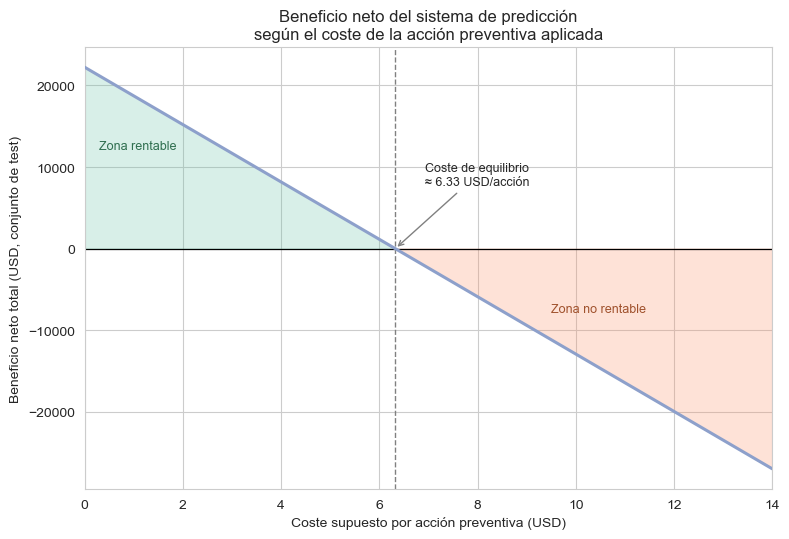

In [7]:
#Figura: beneficio neto según el coste de la acción preventiva
costes = np.linspace(0, 14, 200) #espacio de costes de las acciones preventivas entre 0 y 14 USD/pedido para la representacion
beneficio = ahorro_bruto - costes * n_flagged  #calcilamos beneficio neto, que sera funcion de los costes de aplicar acciones preventivas

fig, ax = plt.subplots(figsize=(8, 5.5))

ax.plot(costes, beneficio, color=PALETTE[2], linewidth=2.2, zorder=3) #dibujamos linea de beficio neto
ax.fill_between(costes, beneficio, 0, where=(beneficio >= 0), color=PALETTE[0], alpha=0.25) #coloreamos zona rentable
ax.fill_between(costes, beneficio, 0, where=(beneficio <= 0), color=PALETTE[1], alpha=0.25) #coloreamos zona no rentable

#linea horizontal en el coste de equilibrio
ax.axhline(0, color="black", linewidth=0.9, zorder=2)
ax.axvline(coste_equilibrio, color="gray", linestyle="--", linewidth=1, zorder=2)
ax.annotate(
    f"Coste de equilibrio\n≈ {coste_equilibrio:.2f} USD/acción",
    xy=(coste_equilibrio, 0),
    xytext=(coste_equilibrio + 0.6, ahorro_bruto * 0.35),           #etiqueta de coste de equilibrio
    fontsize=9,
    arrowprops=dict(arrowstyle="->", color="gray", lw=1),
)

#etiquetas de zona rentable y no rentable
ax.text(0.3, ahorro_bruto * 0.55, "Zona rentable", fontsize=9, color="#2f6f4f")  
ax.text(9.5, -ahorro_bruto * 0.35, "Zona no rentable", fontsize=9, color="#a0522d")

ax.set_xlim(0, 14)
ax.set_xlabel("Coste supuesto por acción preventiva (USD)")
ax.set_ylabel("Beneficio neto total (USD, conjunto de test)")
ax.set_title("Beneficio neto del sistema de predicción\nsegún el coste de la acción preventiva aplicada")

plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "beneficio_neto_coste_equilibrio.pdf"), dpi=300, bbox_inches="tight")
plt.savefig(os.path.join(OUTPUT_DIR, "beneficio_neto_coste_equilibrio.png"), dpi=300, bbox_inches="tight")
plt.show()